# Make the TraCR data usable for this project

## Goal

Create **one simple county-by-year dataset** containing the TraCR measures most useful for community-resilience document analysis.

This notebook does **not** create or estimate data. It only:

1. keeps real county-equivalent rows,
2. selects project-relevant TraCR columns,
3. replaces TraCR's `-99` missing-value code with a blank value,
4. gives the selected columns readable names, and
5. saves one CSV.

There is no imputation, interpolation, composite score, normalization, inflation adjustment, or synthetic value creation.

## What TraCR is

**TraCR** is NIST's **Tracking Community Resilience** dataset. It is a structured collection of county-level and county-equivalent measurements describing infrastructure, housing, transportation, population, economic conditions, health access, and the natural environment.

TraCR is **not** a collection of resilience-plan documents and it is **not** a resilience score. In this project, it provides quantitative context that can be connected to municipal documents by geography and year.

## What the final dataset means

Each row represents **one county or county-equivalent in one year**. Each measure is the value published in the original TraCR CSV for that county and year.

Important limitation: TraCR combines measures with different source schedules. A blank cell means that measure was not observed for that county-year. It does **not** mean zero.

## 1. Set up the notebook

The raw TraCR CSV is the source of every measurement in the final output. The NIST metadata workbook explains the measure IDs, and the Census county file supplies readable county names.

In [1]:
from pathlib import Path
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Keep notebook tables readable.
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 50)

# Project file locations.
PROJECT_ROOT = Path.cwd()
RAW_CSV = PROJECT_ROOT / "datasets" / "TraCR_v1_database.csv"
METADATA_FILE = PROJECT_ROOT / "datasets" / "reference" / "TraCR_Metadata.xlsx"
COUNTY_FILE = PROJECT_ROOT / "datasets" / "reference" / "national_county2020.txt"
OUTPUT_DIR = PROJECT_ROOT / "datasets" / "processed"
OUTPUT_CSV = OUTPUT_DIR / "tracr_project_dataset.csv"

# This checksum prevents us from silently processing a different raw file.
EXPECTED_RAW_SHA256 = "a285d35507313b231565756868454e9ef9da6785809d1a4b572bf78452119901"

for required_file in [RAW_CSV, METADATA_FILE, COUNTY_FILE]:
    assert required_file.exists(), f"Missing required file: {required_file}"

print(f"Raw source: {RAW_CSV.relative_to(PROJECT_ROOT)}")
print(f"Final output: {OUTPUT_CSV.relative_to(PROJECT_ROOT)}")

Raw source: datasets/TraCR_v1_database.csv
Final output: datasets/processed/tracr_project_dataset.csv


## 2. Load and verify the official inputs

FIPS codes are loaded as text so leading zeros are preserved. We also verify that:

- the raw file matches the inspected TraCR v1.0 file,
- every row has a unique TraCR ID,
- every county-year key is unique, and
- the NIST metadata contains the same measure IDs as the CSV.

In [2]:
def sha256_file(path):
    # Return a file checksum without changing the file.
    digest = hashlib.sha256()
    with path.open("rb") as file_handle:
        for block in iter(lambda: file_handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


# Verify the raw file before cleaning it.
raw_hash = sha256_file(RAW_CSV)
assert raw_hash == EXPECTED_RAW_SHA256, "The raw TraCR file is not the expected v1.0 file."

# Load the raw measurements and official measure descriptions.
raw = pd.read_csv(RAW_CSV, dtype={"fips": "string"})
raw["fips"] = raw["fips"].str.strip()
metadata = pd.read_excel(METADATA_FILE, sheet_name="Measures")

measure_columns = [column for column in raw.columns if column not in ["UID", "fips", "period"]]
metadata_ids = set(metadata["Measure ID"].dropna().astype(str))

assert raw["UID"].notna().all() and raw["UID"].is_unique
assert raw.duplicated(["fips", "period"]).sum() == 0
assert set(measure_columns) == metadata_ids

pd.Series({
    "raw rows": len(raw),
    "raw measure columns": len(measure_columns),
    "first year": int(raw["period"].min()),
    "last year": int(raw["period"].max()),
    "unique raw geography codes": int(raw["fips"].nunique()),
}, name="value").to_frame()

,value
raw rows,91272
raw measure columns,101
first year,2000
last year,2021
unique raw geography codes,6817


## 3. Select the measures that match the project goal

The project needs contextual evidence about infrastructure access, housing, transportation, population vulnerability, economic capacity, and environmental setting. We keep 16 measures that directly support those topics.

The selection is deliberately small. The notebook does not claim that these fields form a resilience score.

Counts such as poverty, uninsured population, older population, and households without a vehicle should not be compared across counties without an appropriate denominator. They are preserved as source values here; no ratio is invented.

In [3]:
# TraCR ID -> readable output name, analysis group, and plain-language role.
MEASURES = {
    "INFRA110007": ("broadband_households_pct", "Infrastructure", "Household broadband access"),
    "INFRA140007": ("mean_travel_time_to_work_min", "Transportation", "Average commuting time"),
    "BLTENV220005": ("housing_less_than_15_years_pct", "Housing", "Share of newer housing"),
    "BLTENV220006": ("housing_more_than_30_years_pct", "Housing", "Share of older housing"),
    "BLTENV220009": ("mobile_homes_pct", "Housing", "Mobile-home share"),
    "BLTENV220010": ("owner_occupied_housing_pct", "Housing", "Owner-occupied housing share"),
    "BLTENV220011": ("rental_availability_pct", "Housing", "Rental availability"),
    "SOCWB310006": ("households_no_vehicle_5yr_count", "Access", "Households without a vehicle"),
    "SOCWB310015": ("population_count", "Population", "Total population"),
    "SOCWB310017": ("population_age_65_plus_count", "Population", "Population age 65 and older"),
    "SOCWB330011": ("population_in_poverty_5yr_count", "Economic", "Population in poverty"),
    "SOCWB350007": ("population_no_health_insurance_5yr_count", "Health", "Population without health insurance"),
    "ECNVIT510001": ("unemployment_rate_pct", "Economic", "Unemployment rate"),
    "ECNVIT530006": ("median_household_income_5yr_usd_nominal", "Economic", "Median household income in nominal dollars"),
    "NATENV410003": ("landcover_developed_pct", "Environment", "Developed land-cover share"),
    "NATENV410005": ("landcover_wetland_pct", "Environment", "Wetland share"),
}

measure_guide = pd.DataFrame([
    {
        "measure_id": measure_id,
        "output_column": details[0],
        "group": details[1],
        "why_it_is_included": details[2],
    }
    for measure_id, details in MEASURES.items()
])

assert set(MEASURES).issubset(measure_columns)
measure_guide

,measure_id,output_column,group,why_it_is_included
0,INFRA110007,broadband_households_pct,Infrastructure,Household broadband access
1,INFRA140007,mean_travel_time_to_work_min,Transportation,Average commuting time
2,BLTENV220005,housing_less_than_15_years_pct,Housing,Share of newer housing
3,BLTENV220006,housing_more_than_30_years_pct,Housing,Share of older housing
4,BLTENV220009,mobile_homes_pct,Housing,Mobile-home share
5,BLTENV220010,owner_occupied_housing_pct,Housing,Owner-occupied housing share
6,BLTENV220011,rental_availability_pct,Housing,Rental availability
7,SOCWB310006,households_no_vehicle_5yr_count,Access,Households without a vehicle
8,SOCWB310015,population_count,Population,Total population
9,SOCWB310017,population_age_65_plus_count,Population,Population age 65 and older


## 4. Keep county and county-equivalent rows

TraCR contains real county rows, state summary rows, and placeholder rows. The project dataset keeps only county-equivalent geographies.

Most names come from the Census 2020 county reference. Seven valid historical county-equivalent codes in the TraCR time series are named explicitly because later boundary changes removed them from the 2020 list. Those names are labels only; their measurements still come from TraCR.

In [4]:
# Build the current county lookup from the official Census reference file.
county_lookup = pd.read_csv(COUNTY_FILE, sep="|", dtype="string").assign(
    county_fips=lambda frame: frame["STATEFP"] + frame["COUNTYFP"],
    geography_status="current_county_equivalent",
).rename(columns={
    "STATE": "state_abbr",
    "COUNTYNAME": "county_name",
})[["county_fips", "county_name", "state_abbr", "geography_status"]]

# These are historical county-equivalent labels needed to retain valid older TraCR rows.
historical_counties = pd.DataFrame([
    ("02201", "Prince of Wales-Outer Ketchikan Census Area", "AK"),
    ("02232", "Skagway-Hoonah-Angoon Census Area", "AK"),
    ("02261", "Valdez-Cordova Census Area", "AK"),
    ("02270", "Wade Hampton Census Area", "AK"),
    ("02280", "Wrangell-Petersburg Census Area", "AK"),
    ("46113", "Shannon County", "SD"),
    ("51515", "Bedford city", "VA"),
], columns=["county_fips", "county_name", "state_abbr"])
historical_counties["geography_status"] = "historical_county_equivalent"

geography_lookup = pd.concat(
    [county_lookup, historical_counties], ignore_index=True
).drop_duplicates("county_fips")

# An inner join removes state summaries and placeholders because they are not in the county lookup.
county_rows = raw.merge(
    geography_lookup,
    left_on="fips",
    right_on="county_fips",
    how="inner",
    validate="many_to_one",
)

print(f"Raw rows: {len(raw):,}")
print(f"County-equivalent rows retained: {len(county_rows):,}")
print(f"Non-county rows removed: {len(raw) - len(county_rows):,}")

Raw rows: 91,272
County-equivalent rows retained: 71,164
Non-county rows removed: 20,108


## 5. Clean only what must be cleaned

For the selected measures, TraCR uses the exact value `-99` to mark some missing observations. Keeping `-99` would incorrectly make it look like a real negative measurement, so it is changed to a blank value.

Nothing else is estimated or altered. Rows with no selected measurement at all are removed because they add no usable information to this project dataset.

In [5]:
selected_ids = list(MEASURES)
rename_map = {measure_id: details[0] for measure_id, details in MEASURES.items()}

# Count the explicit missing codes before replacing them.
missing_code_count = int((county_rows[selected_ids] == -99).sum().sum())

# Keep only identifiers and selected source measurements.
clean = county_rows[
    ["county_fips", "county_name", "state_abbr", "geography_status", "period"] + selected_ids
].copy()

# -99 means missing in TraCR; a blank cell is the honest representation.
clean[selected_ids] = clean[selected_ids].replace(-99, np.nan)

# Give the year and measures readable names.
clean = clean.rename(columns={"period": "year", **rename_map})
output_measure_columns = list(rename_map.values())

# Remove rows that contain no usable selected measurement.
clean = clean.dropna(subset=output_measure_columns, how="all")
clean = clean.sort_values(["county_fips", "year"]).reset_index(drop=True)

print(f"-99 cells changed to blank: {missing_code_count:,}")
print(f"Final rows with at least one selected measurement: {len(clean):,}")
print(f"Final columns: {clean.shape[1]:,}")

-99 cells changed to blank: 15
Final rows with at least one selected measurement: 70,902
Final columns: 21


## 6. Prove that no measurement was invented

The checks below reconstruct the expected values directly from the raw TraCR CSV and compare every selected output cell against them. The only allowed difference is that raw `-99` becomes blank.

The notebook stops with an error if a value changes, a duplicate county-year appears, or a percentage falls outside 0–100.

In [6]:
# Rebuild the expected selected values directly from the raw file.
expected = county_rows[["county_fips", "period"] + selected_ids].copy()
expected[selected_ids] = expected[selected_ids].replace(-99, np.nan)
expected = expected.rename(columns={"period": "year", **rename_map})
expected = expected.dropna(subset=output_measure_columns, how="all")
expected = expected.sort_values(["county_fips", "year"]).reset_index(drop=True)

# Every output measurement must match its source value exactly, including blanks.
pd.testing.assert_frame_equal(
    clean[["county_fips", "year"] + output_measure_columns],
    expected[["county_fips", "year"] + output_measure_columns],
    check_dtype=False,
)

assert clean.duplicated(["county_fips", "year"]).sum() == 0
assert not (clean[output_measure_columns] == -99).any().any()

percentage_columns = [column for column in output_measure_columns if column.endswith("_pct")]
for column in percentage_columns:
    observed = clean[column].dropna()
    assert observed.between(0, 100).all(), f"Out-of-range percentage in {column}"

validation_summary = pd.Series({
    "output rows": len(clean),
    "unique county-equivalent codes": clean["county_fips"].nunique(),
    "first year": int(clean["year"].min()),
    "last year": int(clean["year"].max()),
    "duplicate county-year rows": int(clean.duplicated(["county_fips", "year"]).sum()),
    "invented or changed measurement cells": 0,
}, name="result").to_frame()

validation_summary

,result
output rows,70902
unique county-equivalent codes,3228
first year,2000
last year,2021
duplicate county-year rows,0
invented or changed measurement cells,0


## 7. Save one output CSV

This is the only generated data file. It is intentionally wide and readable: one row per county-year and one column per selected TraCR measure.

In [7]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
clean.to_csv(OUTPUT_CSV, index=False)

print(f"Saved: {OUTPUT_CSV.relative_to(PROJECT_ROOT)}")
print(f"Shape: {clean.shape[0]:,} rows x {clean.shape[1]:,} columns")
clean


Saved: datasets/processed/tracr_project_dataset.csv
Shape: 70,902 rows x 21 columns


,county_fips,county_name,state_abbr,geography_status,year,broadband_households_pct,mean_travel_time_to_work_min,housing_less_than_15_years_pct,housing_more_than_30_years_pct,mobile_homes_pct,owner_occupied_housing_pct,rental_availability_pct,households_no_vehicle_5yr_count,population_count,population_age_65_plus_count,population_in_poverty_5yr_count,population_no_health_insurance_5yr_count,unemployment_rate_pct,median_household_income_5yr_usd_nominal,landcover_developed_pct,landcover_wetland_pct
0,01001,Autauga County,AL,current_county_equivalent,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,44021.0,4531.0,NaN,NaN,4.0,NaN,NaN,NaN
1,01001,Autauga County,AL,current_county_equivalent,2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,44889.0,4667.0,NaN,NaN,4.0,NaN,1.58,5.62
2,01001,Autauga County,AL,current_county_equivalent,2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45909.0,4817.0,NaN,NaN,5.0,NaN,NaN,NaN
3,01001,Autauga County,AL,current_county_equivalent,2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46800.0,4994.0,NaN,NaN,5.0,NaN,NaN,NaN
4,01001,Autauga County,AL,current_county_equivalent,2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,48366.0,5190.0,NaN,NaN,5.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70897,72153,Yauco Municipio,PR,current_county_equivalent,2017,44.032003,24.358618,5.836024,69.660978,0.040360,47.249769,3.528598,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
70898,72153,Yauco Municipio,PR,current_county_equivalent,2018,49.314180,23.219450,5.219487,73.403340,0.114764,46.726344,3.138808,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
70899,72153,Yauco Municipio,PR,current_county_equivalent,2019,52.292994,22.693906,4.821643,75.754809,0.114149,47.468752,2.568347,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
70900,72153,Yauco Municipio,PR,current_county_equivalent,2020,NaN,21.854197,4.043119,78.632300,0.113173,49.202128,2.376641,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 8. Show the county coverage for every observed measure-year

Each square represents a year in which the measure has at least one county observation. The number inside the square is the **percentage of retained county-equivalent rows with an observed value** for that year.

Blank space means the measure has no observed county value that year. These percentages are a diagnostic calculated from missingness; they are not added to the cleaned dataset and no measurement is estimated.

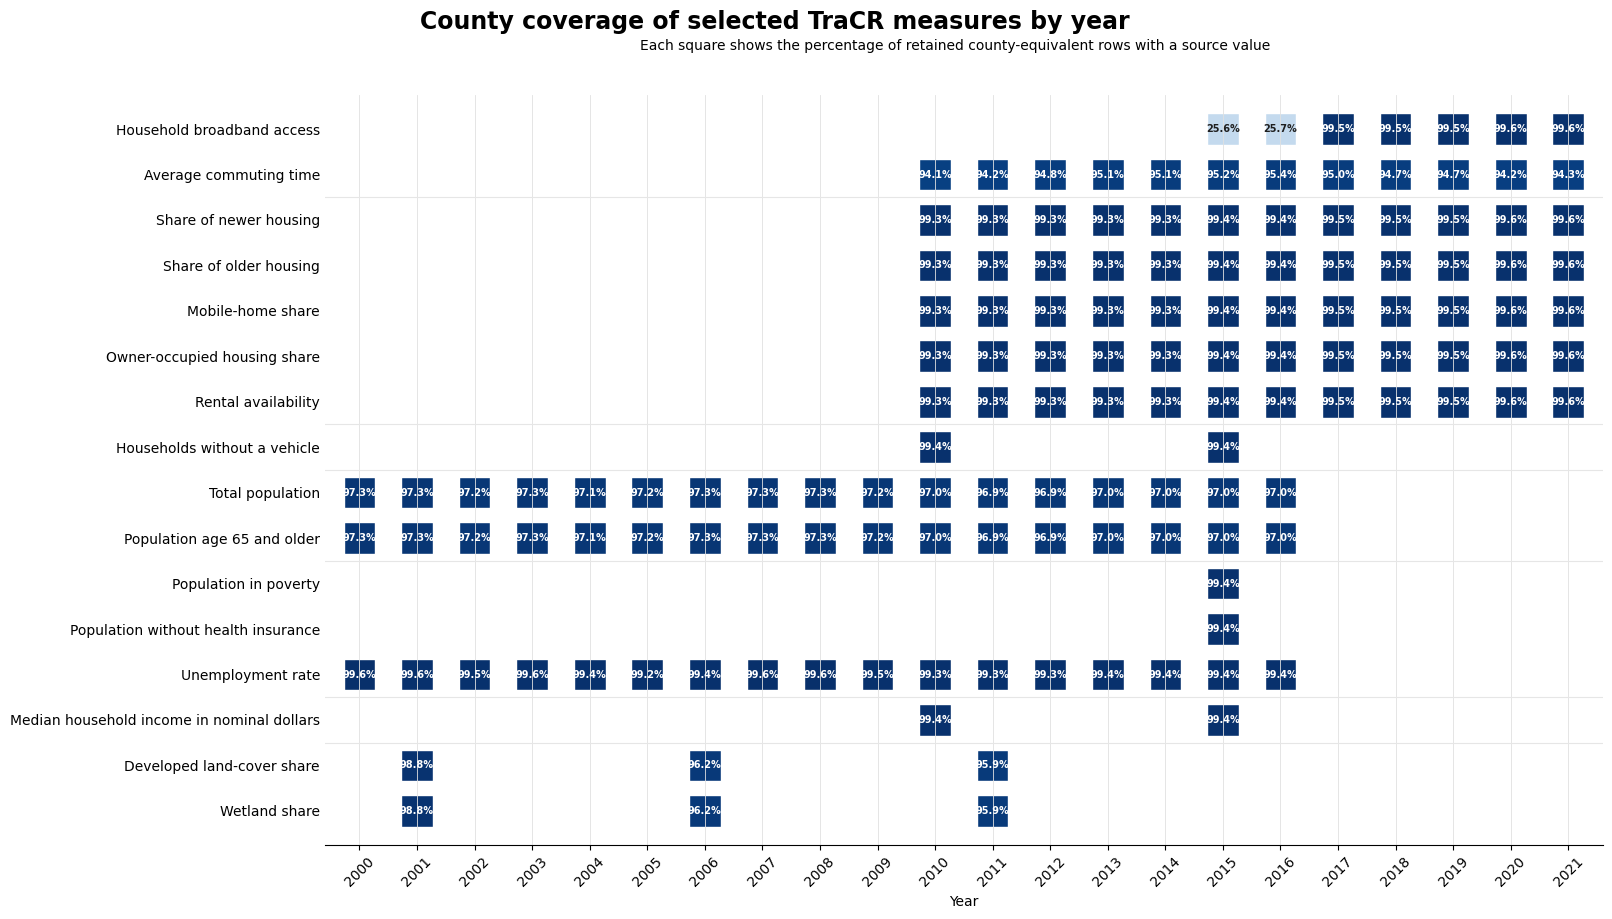

In [8]:
# Use every retained county-equivalent row in each year as the denominator.
all_counties_per_year = county_rows.groupby("period")["county_fips"].nunique()

coverage_records = []
for measure_id, (column, group, label) in MEASURES.items():
    observed_count = clean.groupby("year")[column].count()
    coverage_pct = observed_count / all_counties_per_year.reindex(observed_count.index) * 100

    # Plot a square whenever the source contains at least one county value.
    for year, value in coverage_pct.items():
        if value > 0:
            coverage_records.append({
                "year": int(year),
                "coverage_pct": float(value),
                "label": label,
            })

coverage = pd.DataFrame(coverage_records)

# One row per measure and one labeled square per observed year.
labels = [details[2] for details in MEASURES.values()]
y_position = {label: index for index, label in enumerate(labels)}

fig, axis = plt.subplots(figsize=(18, 10))
fig.subplots_adjust(left=0.25, right=0.96, top=0.88, bottom=0.13)

axis.scatter(
    coverage["year"],
    coverage["label"].map(y_position),
    c=coverage["coverage_pct"],
    cmap="Blues",
    vmin=0,
    vmax=100,
    marker="s",
    s=520,
    edgecolors="white",
    linewidths=1.0,
)

# Put the exact coverage percentage inside every square.
for row in coverage.itertuples(index=False):
    text_color = "white" if row.coverage_pct >= 55 else "#1f1f1f"
    axis.text(
        row.year,
        y_position[row.label],
        f"{row.coverage_pct:.1f}%",
        ha="center",
        va="center",
        fontsize=7,
        fontweight="bold",
        color=text_color,
    )

axis.set_yticks(range(len(labels)), labels)
axis.set_xlim(county_rows["period"].min() - 0.6, county_rows["period"].max() + 0.6)
axis.set_xticks(range(int(county_rows["period"].min()), int(county_rows["period"].max()) + 1))
axis.set_xlabel("Year")
axis.tick_params(axis="x", rotation=45)
axis.tick_params(axis="y", length=0)
axis.grid(axis="x", color="#e0e0e0", linewidth=0.6)
axis.grid(axis="y", visible=False)
axis.spines[["top", "right", "left"]].set_visible(False)
axis.invert_yaxis()

# Thin separators show topic groups without adding extra panels.
for boundary in [1.5, 6.5, 7.5, 9.5, 12.5, 13.5]:
    axis.axhline(boundary, color="#e6e6e6", linewidth=0.8)

fig.suptitle(
    "County coverage of selected TraCR measures by year",
    fontsize=17,
    fontweight="bold",
    y=0.965,
)
fig.text(
    0.60,
    0.925,
    "Each square shows the percentage of retained county-equivalent rows with a source value",
    ha="center",
    fontsize=10,
)

plt.show()

## 9. See what the cleaning process retained

The raw TraCR file contains county rows, state summaries, placeholders, and county-year rows that contain none of the 16 selected project measures.

This plot shows the three main row counts. The decrease is caused by filtering—not by generating replacement observations.

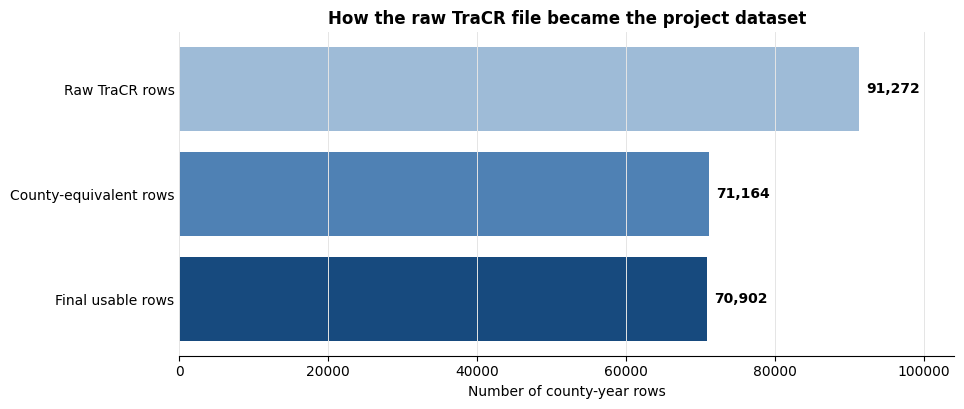

In [9]:
# Compare the number of rows at each stage of the cleaning process.
stage_counts = pd.Series({
    "Raw TraCR rows": len(raw),
    "County-equivalent rows": len(county_rows),
    "Final usable rows": len(clean),
})

fig, axis = plt.subplots(figsize=(10, 4.2))
bars = axis.barh(
    stage_counts.index,
    stage_counts.values,
    color=["#9ebbd7", "#4f81b4", "#174a7e"],
)
axis.invert_yaxis()
axis.set_xlabel("Number of county-year rows")
axis.set_title("How the raw TraCR file became the project dataset", fontweight="bold")
axis.grid(axis="x", color="#e5e5e5", linewidth=0.7)
axis.grid(axis="y", visible=False)
axis.spines[["top", "right", "left"]].set_visible(False)
axis.tick_params(axis="y", length=0)

for bar, value in zip(bars, stage_counts.values):
    axis.text(
        bar.get_width() + 900,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,}",
        va="center",
        fontsize=10,
        fontweight="bold",
    )

axis.set_xlim(0, stage_counts.max() * 1.14)
plt.show()

## 10. See which resilience topics were selected

The original TraCR file contains more measures than this project needs. We selected 16 measures with a direct connection to the project's resilience-document questions.

The chart counts selected fields, not communities or observations. Housing has more fields because housing age, type, tenure, and rental availability represent different contextual questions.

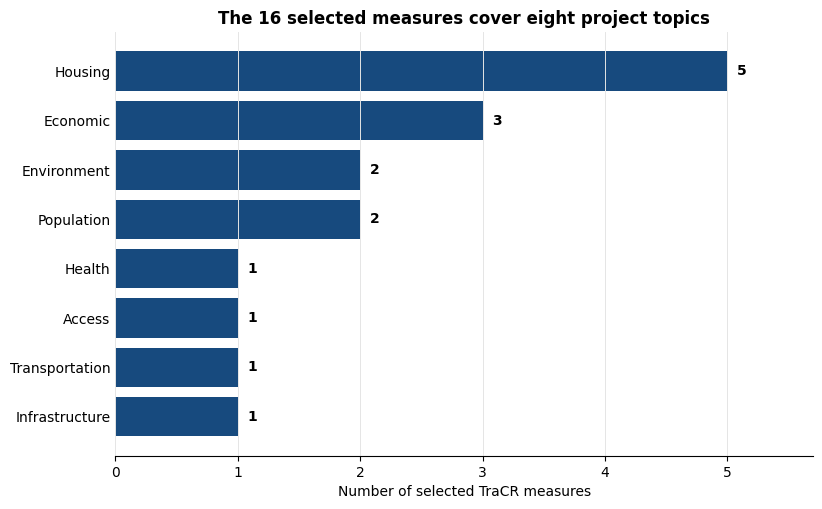

In [10]:
# Count the selected measures in each plain-language topic group.
topic_counts = (
    measure_guide["group"]
    .value_counts()
    .sort_values(ascending=True)
)

fig, axis = plt.subplots(figsize=(9, 5.5))
bars = axis.barh(topic_counts.index, topic_counts.values, color="#174a7e")
axis.set_xlabel("Number of selected TraCR measures")
axis.set_title("The 16 selected measures cover eight project topics", fontweight="bold")
axis.set_xticks(range(0, int(topic_counts.max()) + 1))
axis.grid(axis="x", color="#e5e5e5", linewidth=0.7)
axis.grid(axis="y", visible=False)
axis.spines[["top", "right", "left"]].set_visible(False)
axis.tick_params(axis="y", length=0)

for bar, value in zip(bars, topic_counts.values):
    axis.text(
        bar.get_width() + 0.08,
        bar.get_y() + bar.get_height() / 2,
        str(value),
        va="center",
        fontweight="bold",
    )

axis.set_xlim(0, topic_counts.max() + 0.7)
plt.show()

## 11. See what one TraCR measure looks like across counties

The final dataset does not contain one national value per year. It contains separate county values.

The histogram below uses the latest available unemployment-rate year in the selected data. It shows how county conditions vary during the same year. The median line is a notebook summary only; it is not written into the output CSV.

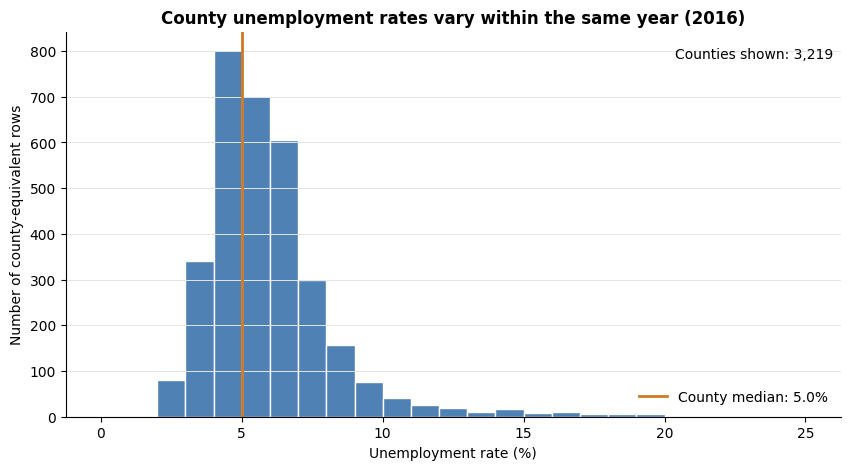

In [11]:
# Use the latest year that contains county unemployment-rate observations.
unemployment_year = int(
    clean.loc[clean["unemployment_rate_pct"].notna(), "year"].max()
)
unemployment_values = clean.loc[
    clean["year"].eq(unemployment_year),
    "unemployment_rate_pct",
].dropna()
unemployment_median = unemployment_values.median()

fig, axis = plt.subplots(figsize=(10, 5))
axis.hist(
    unemployment_values,
    bins=range(0, int(unemployment_values.max()) + 2),
    color="#4f81b4",
    edgecolor="white",
)
axis.axvline(
    unemployment_median,
    color="#d17a22",
    linewidth=2,
    label=f"County median: {unemployment_median:.1f}%",
)
axis.set_title(
    f"County unemployment rates vary within the same year ({unemployment_year})",
    fontweight="bold",
)
axis.set_xlabel("Unemployment rate (%)")
axis.set_ylabel("Number of county-equivalent rows")
axis.grid(axis="y", color="#e5e5e5", linewidth=0.7)
axis.grid(axis="x", visible=False)
axis.spines[["top", "right"]].set_visible(False)
axis.legend(frameon=False)
axis.text(
    0.99,
    0.93,
    f"Counties shown: {len(unemployment_values):,}",
    transform=axis.transAxes,
    ha="right",
    fontsize=10,
)
plt.show()

## 12. See how TraCR can support the Orlando document work

The municipal-document demo focuses on Orlando. TraCR is county-level, so the relevant contextual geography is **Orange County, Florida (`12095`)**.

These two source measures illustrate how document findings could be accompanied by local quantitative context. They do not measure the content or quality of Orlando's plans, and county conditions must not be presented as city-specific measurements.

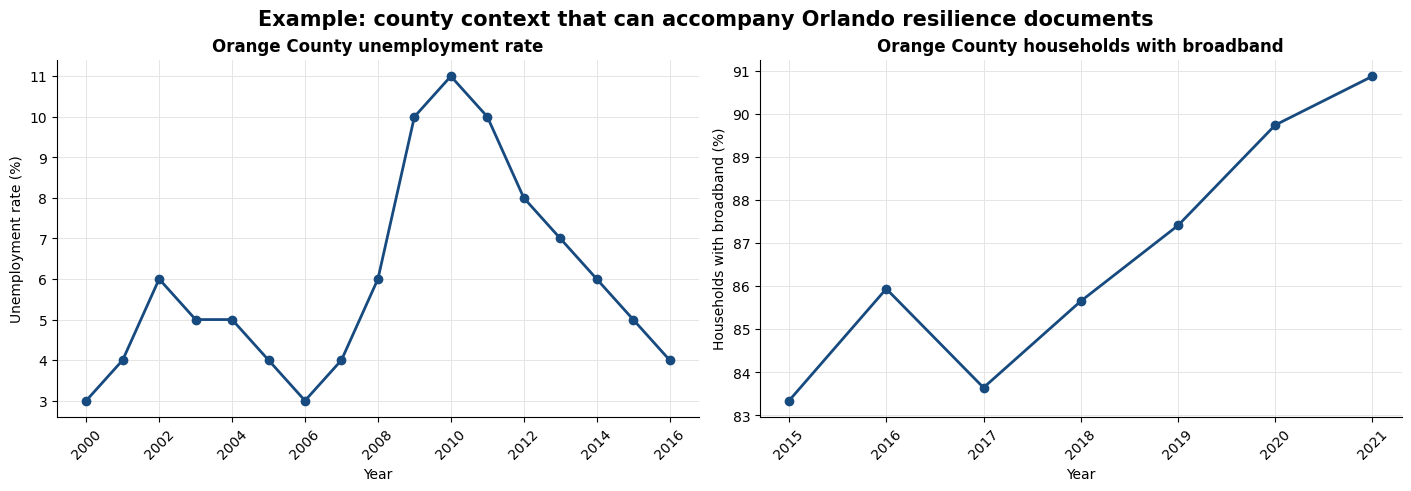

In [12]:
# Use source values for Orange County, Florida—the county containing Orlando.
orange_county = clean.loc[clean["county_fips"].eq("12095")].copy()
assert not orange_county.empty, "Orange County, Florida is missing from the cleaned data."

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)

unemployment = orange_county.dropna(subset=["unemployment_rate_pct"])
axes[0].plot(
    unemployment["year"],
    unemployment["unemployment_rate_pct"],
    color="#174a7e",
    marker="o",
    linewidth=2,
)
axes[0].set_title("Orange County unemployment rate", fontweight="bold")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Unemployment rate (%)")

broadband = orange_county.dropna(subset=["broadband_households_pct"])
axes[1].plot(
    broadband["year"],
    broadband["broadband_households_pct"],
    color="#174a7e",
    marker="o",
    linewidth=2,
)
axes[1].set_title("Orange County households with broadband", fontweight="bold")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Households with broadband (%)")

for axis in axes:
    axis.grid(color="#e5e5e5", linewidth=0.7)
    axis.spines[["top", "right"]].set_visible(False)
    axis.tick_params(axis="x", rotation=45)

fig.suptitle(
    "Example: county context that can accompany Orlando resilience documents",
    fontsize=15,
    fontweight="bold",
)
plt.show()

## 13. Slide-ready summary

### What TraCR is

- NIST's Tracking Community Resilience dataset.
- Structured county and county-equivalent measurements covering 2000–2021.
- Includes infrastructure, transportation, housing, population, economic, health, and environmental context.
- It is contextual numeric data—not municipal documents and not a resilience score.

### What we did

- Verified the raw TraCR v1.0 file and its official metadata.
- Kept real county and county-equivalent rows; removed state summaries and placeholder geographies.
- Selected 16 measures that match the project's community-resilience questions.
- Converted TraCR's `-99` missing-value code to blank values.
- Renamed fields so they are understandable without memorizing measure IDs.
- Produced one readable dataset with 70,902 county-year rows and 21 columns.
- Reconciled every output measurement with the raw source; no values were invented or imputed.

### Why we did it this way

- The raw file mixes geographic levels and uses coded measure names, so it is difficult to join and interpret directly.
- Treating `-99` as a real number would create false negative measurements.
- Measure availability changes by year, so missingness must remain visible instead of being filled in.
- A focused measure set is easier to explain and better aligned with the document-analysis questions.
- One output CSV keeps the workflow simple, reproducible, and auditable.

### How it can be used in this project

- Add county and year context to municipal resilience documents.
- Compare document themes with local housing, access, economic, health, or environmental conditions.
- Group communities for later NLP comparisons without claiming that context causes document language.
- Identify where data coverage is strong enough for a proposed comparison.
- Provide quantitative background for case studies such as the Orlando/Orange County demo.

### Important limitations

- TraCR is county-level; many project documents are city-level.
- Measures come from different sources and years and cannot automatically be compared as one index.
- Counts require appropriate denominators before cross-county comparisons.
- The cleaned fields should not be treated as a causal model or an official resilience ranking.

## 14. How to use the final dataset

- Join or filter rows using `county_fips` and `year`.
- Use the readable measure columns as county context for documents from the same place and period.
- Treat blanks as unavailable observations, not zeros.
- Keep `geography_status` when historical boundary changes matter.
- Do not compare raw count fields across counties without a valid denominator.
- Do not combine these fields into a resilience score unless the project later defines and justifies that method.

The final dataset is a cleaned, smaller view of TraCR. It is not a newly estimated dataset.